# Student Performance Prediction & Analytics
**Course:** INT234 — Predictive Analytics  
**Syllabus coverage:** Units I–IV

## Project objective
This notebook demonstrates how to explore and prepare a student performance dataset, predict final exam scores, classify Pass/Fail, and discover groups using K-Means clustering.

> **Dataset note:** The included dataset is synthetic demo data created for practice. It does not contain real student records and should not be used to make real academic decisions.

## 1. Import libraries and dataset
We use pandas for data handling, matplotlib for charts, and scikit-learn for machine-learning models and evaluation.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

df = pd.read_csv("student_performance.csv")
df = df.drop_duplicates().copy()

features = [
    "study_hours_per_day",
    "attendance_percent",
    "previous_exam_score",
    "assignment_score"
]

df.head()

,study_hours_per_day,attendance_percent,previous_exam_score,assignment_score,final_exam_score
0,4.3,98.7,69.7,77.5,41.0
1,2.0,59.6,53.3,73.4,33.7
2,5.1,88.4,81.1,69.9,64.0
3,5.4,74.1,52.6,94.2,53.7
4,0.5,77.3,52.5,63.3,28.2


## 2. Data Analysis aur 3 graphs


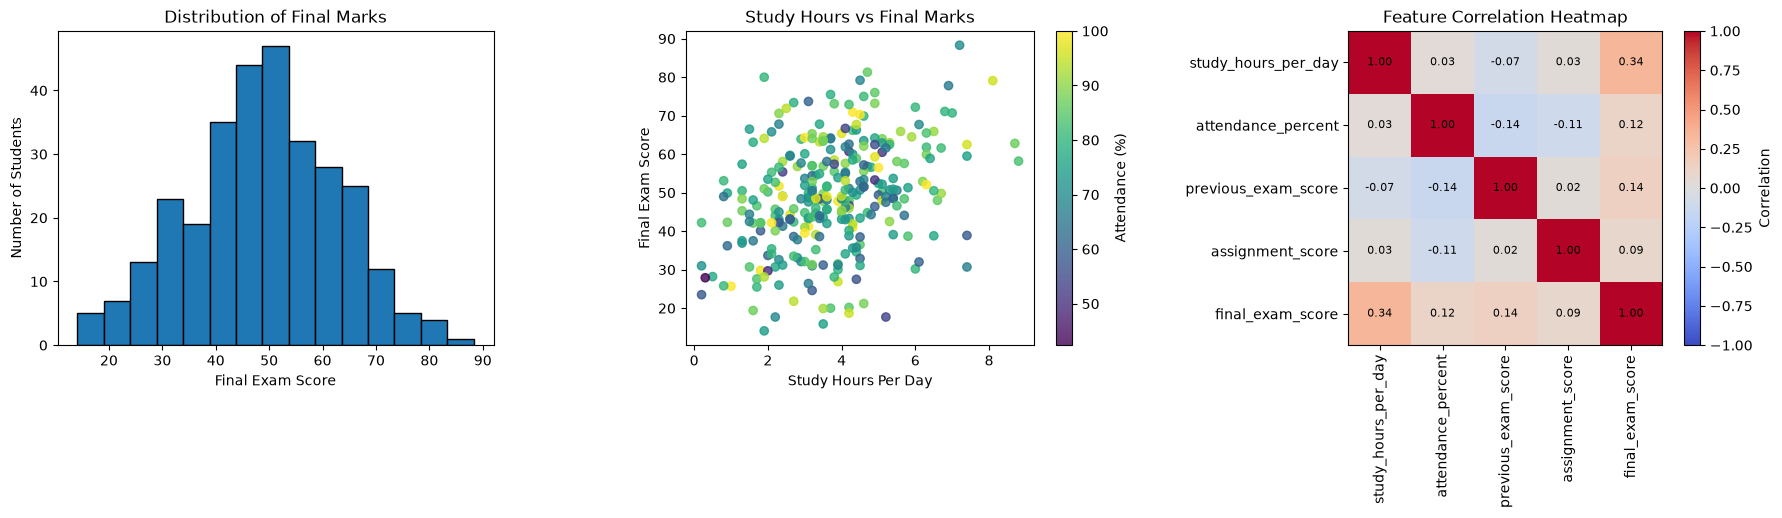

Missing Values:


,Missing Values
study_hours_per_day,0
attendance_percent,0
previous_exam_score,0
assignment_score,0
final_exam_score,0


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Graph 1: Final marks distribution
ax[0].hist(
    df["final_exam_score"],
    bins=15,
    edgecolor="black"
)
ax[0].set_title("Distribution of Final Marks")
ax[0].set_xlabel("Final Exam Score")
ax[0].set_ylabel("Number of Students")

# Graph 2: Study hours vs marks
scatter = ax[1].scatter(
    df["study_hours_per_day"],
    df["final_exam_score"],
    c=df["attendance_percent"],
    cmap="viridis",
    alpha=0.8
)
ax[1].set_title("Study Hours vs Final Marks")
ax[1].set_xlabel("Study Hours Per Day")
ax[1].set_ylabel("Final Exam Score")
fig.colorbar(scatter, ax=ax[1], label="Attendance (%)")

# Graph 3: Correlation heatmap
corr = df[features + ["final_exam_score"]].corr()

im = ax[2].imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax[2].set_title("Feature Correlation Heatmap")
ax[2].set_xticks(range(len(corr.columns)))
ax[2].set_xticklabels(corr.columns, rotation=90)
ax[2].set_yticks(range(len(corr.columns)))
ax[2].set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax[2].text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(im, ax=ax[2], label="Correlation")
plt.tight_layout()
plt.show()

print("Missing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

## 3. Linear Regression


LINEAR REGRESSION RESULTS
-------------------------
MAE  : 9.41
MSE  : 142.15
RMSE : 11.92
R2 Score: 0.155


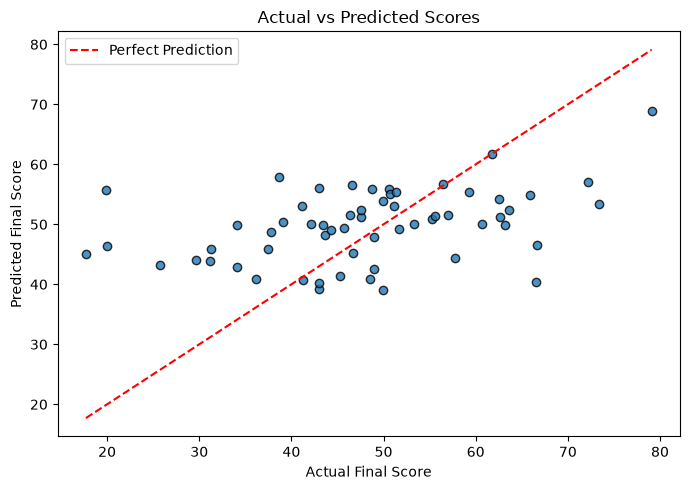

In [7]:
X = df[features]
y = df["final_exam_score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

regression_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

regression_model.fit(X_train, y_train)

y_pred = regression_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2 Score: {r2:.3f}")

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.8,
    edgecolor="black"
)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot(
    [low, high],
    [low, high],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Actual vs Predicted Scores")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Classification Pass/Fail
Convert columns to numeric, remove duplicate rows, and fill missing numeric values with each column's median. The model pipelines below also include imputation so missing values are handled safely during training.

PASS/FAIL CLASSIFICATION RESULTS
--------------------------------
Accuracy  : 0.767
Precision : 0.776
Recall    : 0.978
F1 Score  : 0.865


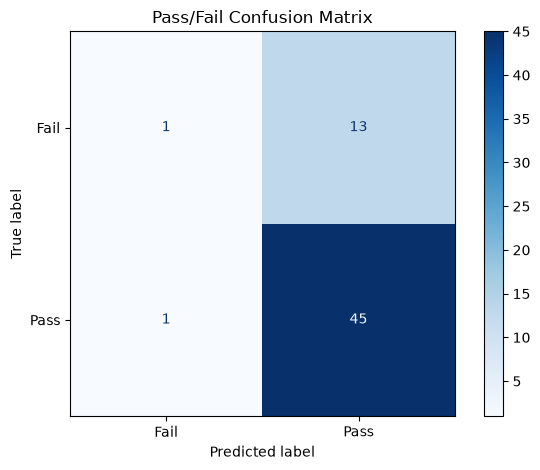

In [8]:
df["pass_fail"] = (
    df["final_exam_score"] >= 40
).astype(int)

X_class = df[features]
y_class = df["pass_fail"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

classification_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

classification_model.fit(X_train_c, y_train_c)

y_class_pred = classification_model.predict(X_test_c)

print("PASS/FAIL CLASSIFICATION RESULTS")
print("--------------------------------")
print(f"Accuracy  : {accuracy_score(y_test_c, y_class_pred):.3f}")
print(f"Precision : {precision_score(y_test_c, y_class_pred, zero_division=0):.3f}")
print(f"Recall    : {recall_score(y_test_c, y_class_pred, zero_division=0):.3f}")
print(f"F1 Score  : {f1_score(y_test_c, y_class_pred, zero_division=0):.3f}")

cm = confusion_matrix(
    y_test_c,
    y_class_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Pass/Fail Confusion Matrix")
plt.tight_layout()
plt.show()

## 5 — K-Means clustering
K-Means is an unsupervised learning algorithm. Here, we use the four input features to explore three groups. Features are scaled because they have different numeric ranges.

Cluster labels (0, 1, 2) are arbitrary IDs; they do not automatically mean low, medium, or high performance.

CLUSTER SUMMARY


,study_hours_per_day,attendance_percent,previous_exam_score,assignment_score,final_exam_score
cluster,,,,,
0,2.88,70.89,70.57,79.38,47.96
1,5.53,76.03,60.66,73.27,54.42
2,3.11,85.43,51.85,65.58,45.90


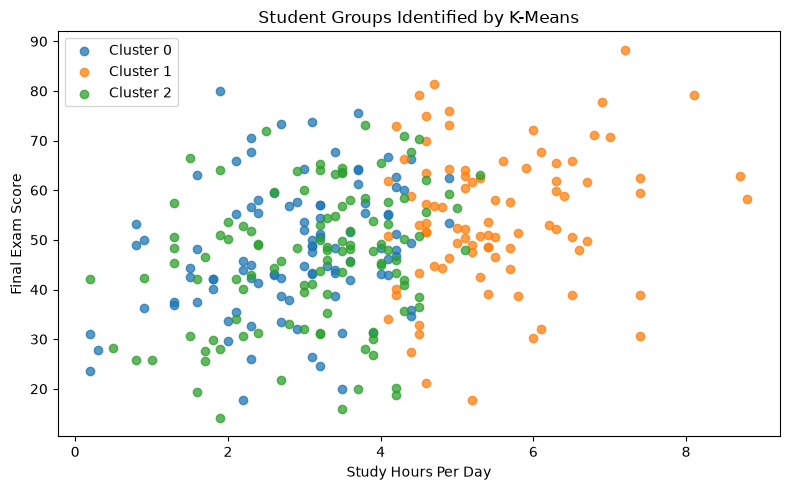

In [10]:
cluster_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )
)

df["cluster"] = cluster_pipeline.fit_predict(
    df[features]
)

print("CLUSTER SUMMARY")

display(
    df.groupby("cluster")[
        features + ["final_exam_score"]
    ].mean().round(2)
)

plt.figure(figsize=(8, 5))

for cluster_id in sorted(df["cluster"].unique()):
    subset = df[df["cluster"] == cluster_id]

    plt.scatter(
        subset["study_hours_per_day"],
        subset["final_exam_score"],
        label=f"Cluster {cluster_id}",
        alpha=0.75
    )

plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Exam Score")
plt.title("Student Groups Identified by K-Means")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Final Results aur CSV Export
This creates a CSV file that you can open in Excel.

In [11]:
summary = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score",
        "Classification Accuracy",
        "Classification Precision",
        "Classification Recall",
        "Classification F1 Score"
    ],
    "Value": [
        mae,
        mse,
        rmse,
        r2,
        accuracy_score(y_test_c, y_class_pred),
        precision_score(y_test_c, y_class_pred, zero_division=0),
        recall_score(y_test_c, y_class_pred, zero_division=0),
        f1_score(y_test_c, y_class_pred, zero_division=0)
    ]
})

print("FINAL MODEL PERFORMANCE")
display(summary.round(3))

# Export dataset with Pass/Fail and cluster labels
output_file = "student_performance_with_clusters.csv"

df.to_csv(output_file, index=False)

print("Project completed successfully!")
print("Output file:", output_file)

FINAL MODEL PERFORMANCE


,Metric,Value
0,MAE,9.409
1,MSE,142.154
2,RMSE,11.923
3,R2 Score,0.155
4,Classification Accuracy,0.767
5,Classification Precision,0.776
6,Classification Recall,0.978
7,Classification F1 Score,0.865


Project completed successfully!
Output file: student_performance_with_clusters.csv


## 6. Unit II — Regression: predict final exam score
Linear Regression predicts a continuous numeric value. We train on 80% of the rows and evaluate on the remaining 20%.

- **MAE:** average absolute prediction error.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE.
- **R²:** indicates how well predictions explain variation in the test target.

## 11. Conclusion
This notebook demonstrates four syllabus areas:
1. **Unit I:** data exploration and preprocessing.
2. **Unit II:** Linear Regression and regression metrics.
3. **Unit III:** Pass/Fail classification and classification metrics.
4. **Unit IV:** K-Means clustering and cluster summaries.

The included records are synthetic. Results show how the methods work, not how well they would perform on real student data.

## Viva questions
**1. What is predictive analytics?**  
It uses data and analytical methods to predict outcomes or identify patterns.

**2. What is data preprocessing?**  
Preparing data for analysis, for example handling missing values and duplicates.

**3. What is Linear Regression used for here?**  
To predict a continuous value, the final exam score.

**4. What does MAE mean?**  
Mean Absolute Error is the average absolute difference between actual and predicted values.

**5. What is classification?**  
Predicting a category, such as Pass or Fail.

**6. What is a confusion matrix?**  
A table comparing actual classes with predicted classes.

**7. What is K-Means?**  
An unsupervised algorithm that groups data points into K clusters based on similarity.

**8. Why scale features for K-Means?**  
To prevent features with larger numeric ranges from dominating distance calculations.